# 05: Logistic Regression (Kişi 1)

**Proje:** Framingham Kalp Çalışması verisi ile inme (stroke) tahmini

**Bu notebook'ta yapılanlar:**
1. Modelin seçilme gerekçesi
2. Dengeleme yöntemlerinin karşılaştırılması (yok / class_weight / SMOTE)
3. Hiperparametre araması (GridSearchCV, 5 katlı katmanlı CV, PR-AUC)
4. En iyi modelin CV değerlendirmesi ve overfitting kontrolü
5. Karar eşiğinin seçimi
6. Katsayıların yorumlanması (odds ratio)
7. Test seti değerlendirmesi (bir kez)
8. Açıklanabilir yapay zeka: SHAP + LIME

Ortak fonksiyonlar `src/` klasöründedir: `preprocessing.py` (veri ve pipeline), `metrics.py` (değerlendirme), `explain.py` (XAI).

## 1. Kurulum ve sabitler

In [1]:
MODEL_CODE = "lr"
MODEL_NAME = "Logistic Regression"

In [2]:
# shap and lime are not preinstalled on Colab
try:
    import lime
    import shap
except ImportError:
    %pip install -q shap lime

In [3]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# Repo: ../src. Colab: the src/*.py files uploaded to the working directory.
SRC_DIR = next((p for p in (Path("../src"), Path("src"), Path(".")) if (p / "config.py").exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("config.py bulunamadı. Colab'da src klasöründeki .py dosyalarını sol menüden yükleyin.")
sys.path.insert(0, str(SRC_DIR.resolve()))

from config import MAIN_METRIC, RANDOM_STATE, TARGET_RECALL
from explain import explain
from metrics import (SCORING, cv_evaluate, learning_curve_analysis, shared_cv, test_evaluate,
                     threshold_analysis)
from preprocessing import build_pipeline, load_data

# Output folders: repo root (one level above src) or the Colab working directory
ROOT = SRC_DIR.resolve().parent if SRC_DIR.resolve().name == "src" else Path.cwd()
MODEL_DIR, FIG_DIR = ROOT / "models", ROOT / "figures"
MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", None)

In [4]:
X_train, X_test, y_train, y_test = load_data()
print("Eğitim:", X_train.shape, "| inme oranı: %.2f%%" % (y_train.mean() * 100))
print("Test:  ", X_test.shape, "| inme oranı: %.2f%%" % (y_test.mean() * 100))

Eğitim: (3521, 17) | inme oranı: 8.69%
Test:   (881, 17) | inme oranı: 8.74%


## 2. Neden Logistic Regression?

Logistic Regression, özelliklerin ağırlıklı toplamını sigmoid fonksiyonundan geçirerek 0 ile 1 arasında bir **inme olasılığı** üretir:

$$P(\text{inme}) = \frac{1}{1 + e^{-(b_0 + b_1 x_1 + \dots + b_n x_n)}}$$

| Neden seçildi | Açıklama |
|---|---|
| Tıpta standart yöntem | Klinik risk skorlarının çoğu bu aileden modellere dayanır. Framingham'ın kendi inme risk profili (Wolf vd., 1991) de yaş, tansiyon, diyabet, sigara gibi faktörlerin ağırlıklı toplamıdır. |
| Temel çizgi (baseline) | Basit ve hızlıdır. Daha karmaşık modellerin (RF, XGBoost) bu modeli ne kadar geçtiği, karmaşıklığın değip değmediğini gösterir. |
| Yorumlanabilir | Her katsayı, ilgili özelliğin inme riskini (log-odds olarak) ne kadar artırdığını veya azalttığını doğrudan söyler. |

**Zayıf yanı:** Özellik ile risk arasında yalnızca doğrusal (log-odds ölçeğinde) bir ilişki öğrenir. Eşik etkileri ve özellikler arası etkileşimler (ör. "yaşlı **ve** tansiyonu yüksek") ancak elle eklenen özelliklerle yakalanabilir. Bu projede `bp_stage`, `bmi_category` ve `comorbidity_count` bu eksikliği kısmen kapatır.

**Ölçekleme şart mı?** Evet. Düzenlileştirme (regularization) bütün katsayıları aynı ölçüde cezalandırdığı için sütunların ölçekleri aynı olmalıdır. Pipeline'daki `StandardScaler` bunu sağlar.

## 3. Dengeleme yöntemlerinin karşılaştırılması

Varsayılan hiperparametrelerle üç seçenek denenir. Amaç: inme sınıfı azınlıkta iken hangi dengeleme yöntemi bu model için daha iyi?

- `none`: dengeleme yok
- `class_weight`: azınlık sınıfı (inme) hataları daha ağır cezalandırılır (`class_weight="balanced"`)
- `smote`: eğitim katlarına sentetik inme örnekleri eklenir

Bu satırlar keşif amaçlıdır, `results.csv`'ye yazılmaz (`save=False`). Tabloya yalnızca en iyi model yazılır.

In [5]:
balancing_rows = {}
for balancing in ("none", "class_weight", "smote"):
    pipe = build_pipeline(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE), balancing=balancing)
    res = cv_evaluate(pipe, X_train, y_train, model_name=MODEL_NAME, save=False, verbose=False)
    balancing_rows[balancing] = res["summary"]["cv_mean"]

balancing_table = pd.DataFrame(balancing_rows).T
balancing_table.index.name = "balancing"
balancing_table.round(3)

metric,recall,precision,f1,specificity,roc_auc,pr_auc,accuracy
balancing,,,,,,,
none,0.007,0.200,0.013,0.999,0.717,0.199,0.913
class_weight,0.627,0.153,0.246,0.669,0.715,0.200,0.666
smote,0.542,0.147,0.231,0.701,0.684,0.185,0.688


**Okuma:**
- **Dengeleme yoksa** model eşik 0.5'te neredeyse hiç "inme var" demiyor (recall ≈ 0.01). Accuracy %91 ile en yüksek görünüyor ama bu, herkese "inme yok" demenin sonucu: dengesiz veride accuracy'nin neden yanıltıcı olduğunun somut örneği.
- **class_weight** ve **SMOTE** olasılıkları yukarı çekerek recall'u 0.5–0.6'ya çıkarıyor, karşılığında precision ve specificity düşüyor.
- Eşikten bağımsız metrikler (ROC-AUC, PR-AUC) "none" ve "class_weight"te neredeyse aynı: Logistic Regression'da sınıf ağırlığı kişilerin risk **sıralamasını** pek değiştirmez, olasılıkları kaydırır. Varsayılan ayarlarda SMOTE biraz daha düşük; bunun nedeni Bölüm 4'te görülüyor.

Karar eşiği zaten Bölüm 6'da ayrıca seçileceği için, asıl seçim ölçütü eşikten bağımsız olan **PR-AUC**'dir.

## 4. Hiperparametre araması

| Hiperparametre | Denenen değerler | Anlamı |
|---|---|---|
| `C` | 0.001, 0.01, 0.1, 1, 10 | Düzenlileştirme gücünün tersi. Küçük C = güçlü düzenlileştirme = daha basit model (katsayılar sıfıra çekilir), overfitting'e karşı korur. |
| `penalty` | `l1`, `l2` | L2 (Ridge) katsayıları küçültür. L1 (Lasso) gereksiz katsayıları tam sıfıra indirerek özellik seçimi yapar. |
| dengeleme | `class_weight`, `smote` | Bölüm 3'teki iki dengeleme yöntemi |

`solver="liblinear"` hem L1 hem L2'yi destekler ve bu boyuttaki veri için hızlıdır. Arama ekibin ortak CV katlarıyla (`shared_cv()`) yapılır ve en iyi model **PR-AUC**'ye göre seçilir (`refit=MAIN_METRIC`). Test seti bu aşamada hiç kullanılmaz.

In [6]:
param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10],
    "model__penalty": ["l1", "l2"],
}

searches = {}
for balancing in ("class_weight", "smote"):
    pipe = build_pipeline(
        LogisticRegression(solver="liblinear", max_iter=3000, random_state=RANDOM_STATE),
        balancing=balancing)
    search = GridSearchCV(pipe, param_grid, cv=shared_cv(), scoring=SCORING,
                          refit=MAIN_METRIC, n_jobs=-1)
    search.fit(X_train, y_train)
    searches[balancing] = search
    print(f"{balancing:12s} | en iyi {MAIN_METRIC} = {search.best_score_:.3f} | {search.best_params_}")

best_balancing = max(searches, key=lambda b: searches[b].best_score_)
search = searches[best_balancing]
best = search.best_estimator_
print(f"\nSeçilen: balancing = {best_balancing}, {search.best_params_}")

class_weight | en iyi pr_auc = 0.207 | {'model__C': 0.01, 'model__penalty': 'l2'}


smote        | en iyi pr_auc = 0.208 | {'model__C': 0.001, 'model__penalty': 'l2'}

Seçilen: balancing = smote, {'model__C': 0.001, 'model__penalty': 'l2'}


In [7]:
# Every combination tried, sorted by PR-AUC (CV mean)
rows = []
for balancing, s in searches.items():
    r = pd.DataFrame(s.cv_results_)
    r["balancing"] = balancing
    rows.append(r)
grid = pd.concat(rows)
cols = ["balancing", "param_model__penalty", "param_model__C",
        "mean_test_pr_auc", "std_test_pr_auc", "mean_test_roc_auc", "mean_test_recall", "mean_test_f1"]
grid[cols].sort_values("mean_test_pr_auc", ascending=False).head(10).round(3).reset_index(drop=True)

,balancing,param_model__penalty,param_model__C,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc,mean_test_recall,mean_test_f1
0,smote,l2,0.001,0.208,0.020,0.716,0.624,0.237
1,class_weight,l2,0.010,0.207,0.022,0.720,0.644,0.245
2,class_weight,l1,0.100,0.206,0.022,0.721,0.637,0.243
3,class_weight,l2,0.100,0.205,0.018,0.718,0.650,0.252
4,class_weight,l1,0.010,0.205,0.022,0.722,0.755,0.242
5,class_weight,l2,0.001,0.204,0.021,0.714,0.654,0.238
6,class_weight,l1,1.000,0.202,0.020,0.717,0.644,0.251
7,class_weight,l2,1.000,0.200,0.020,0.715,0.631,0.247
8,class_weight,l2,10.000,0.199,0.020,0.714,0.624,0.244
9,class_weight,l1,10.000,0.199,0.020,0.714,0.627,0.245


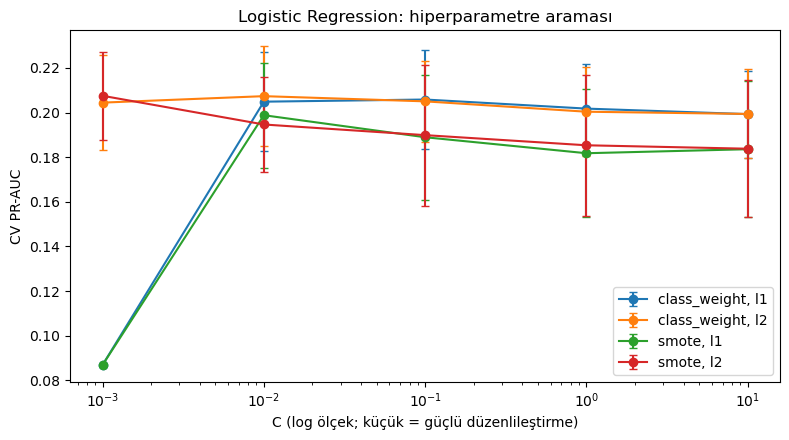

In [8]:
# PR-AUC as a function of C, per penalty and balancing
fig, ax = plt.subplots(figsize=(8, 4.5))
for (balancing, penalty), g in grid.groupby(["balancing", "param_model__penalty"]):
    g = g.sort_values("param_model__C")
    ax.errorbar(g["param_model__C"].astype(float), g["mean_test_pr_auc"], yerr=g["std_test_pr_auc"],
                marker="o", capsize=3, label=f"{balancing}, {penalty}")
ax.set_xscale("log")
ax.set_xlabel("C (log ölçek; küçük = güçlü düzenlileştirme)")
ax.set_ylabel("CV PR-AUC")
ax.set_title(f"{MODEL_NAME}: hiperparametre araması")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_grid_search.png", dpi=200)
plt.show()

**Okuma:**
- **L1 + C = 0.001** bütün katsayıları sıfıra indiriyor: model herkese aynı olasılığı veriyor ve PR-AUC, inme oranına (≈ 0.087) düşüyor. Aşırı düzenlileştirmenin (underfitting) uç örneği.
- **SMOTE ile** küçük C (güçlü düzenlileştirme) daha iyi: SMOTE'un ürettiği sentetik inme örnekleri gerçek örneklere çok benzediği için model bunları ezberlemeye yatkın; güçlü düzenlileştirme bunu frenliyor. Varsayılan C = 1'de SMOTE'un Bölüm 3'te geride kalmasının nedeni bu.
- **class_weight ile** C = 0.01–0.1 arası en iyi, ama farklar çok küçük.
- En iyi iki ayar (SMOTE, C = 0.001, L2 ve class_weight, C = 0.01, L2) arasındaki fark (0.001), katlar arası standart sapmanın (≈ 0.02) çok altında: ikisi arasında gerçek bir fark yok. Seçim kuralı gereği PR-AUC'si en yüksek olan alındı.

## 5. En iyi modelin CV değerlendirmesi ve overfitting kontrolü

`cv_evaluate` en iyi modeli ortak 5 katta sıfırdan eğitir, her katta eğitim ve doğrulama skorlarını hesaplar ve sonucu `results.csv`'ye ekler. **Eğitim - CV farkı (gap)** büyükse model eğitim verisini ezberlemiş demektir.

In [9]:
note = f"GridSearch: balancing={best_balancing}, " + ", ".join(f"{k.split('__')[1]}={v}" for k, v in search.best_params_.items())
result = cv_evaluate(best, X_train, y_train, model_name=MODEL_NAME, note=note)

===== Logistic Regression: 5 katlı CV (eşik = 0.5) =====
Kat başına ortalama eğitim süresi: 0.02 sn

             train_mean  cv_mean  cv_std    gap
metric                                         
recall            0.672    0.624   0.098  0.047
precision         0.158    0.146   0.018  0.012
f1                0.256    0.237   0.030  0.019
specificity       0.659    0.654   0.019  0.005
roc_auc           0.730    0.716   0.034  0.015
pr_auc            0.208    0.208   0.022  0.001
accuracy          0.660    0.652   0.015  0.009

Sonuç 'results.csv' dosyasına eklendi.


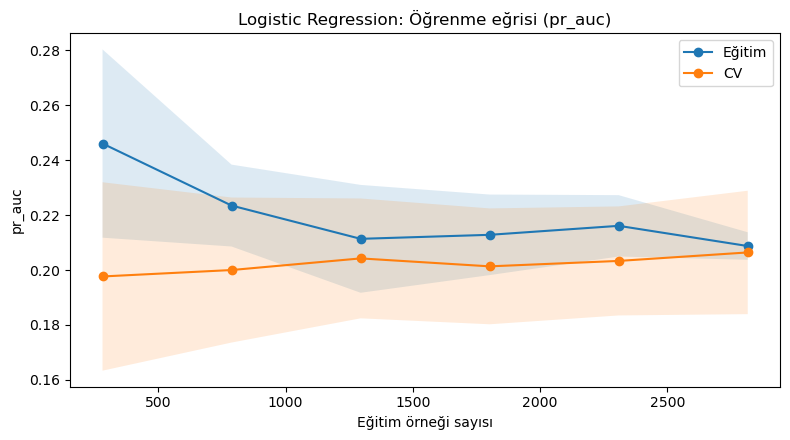

,train_size,train_mean,cv_mean,cv_std
0,281,0.246,0.198,0.034
1,788,0.223,0.200,0.026
2,1295,0.211,0.204,0.022
3,1802,0.213,0.201,0.021
4,2309,0.216,0.203,0.020
5,2816,0.209,0.206,0.022


In [10]:
lc = learning_curve_analysis(best, X_train, y_train, model_name=MODEL_NAME)
plt.close("all")
lc.round(3)

**Okuma:** Eğitim ve CV skorları birbirine yakınsa model ezberlemiyor demektir. Logistic Regression az parametreli ve düzenlileştirilmiş bir model olduğu için overfitting riski düşüktür. Eğitim verisi büyüdükçe iki eğri birbirine yaklaşır. Her ikisinin de görece düşük kalması ise modelin daha karmaşık örüntüleri yakalayamadığını (hafif underfitting) gösterir. Bu, doğrusal bir modelin bilinen sınırıdır ve ağaç modelleriyle karşılaştırırken tartışılacak noktadır.

## 6. Karar eşiğinin seçimi

Model her kişi için bir inme olasılığı üretir. Varsayılan eşik (0.5) bu veride uygun değildir: inmeyi kaçırmak, yanlış alarmdan daha pahalıdır. Eşik, **test setine bakılmadan**, CV tahminleri (out-of-fold) üzerinde seçilir: recall en az %80 olacak şekilde en yüksek eşik (yani bu recall'u en az yanlış alarmla sağlayan eşik).

===== Logistic Regression: Eşik analizi (toplam 306 inme, 3521 kişi) =====
 threshold  caught  missed  false_alarms  recall  precision  specificity  false_alarms_per_1000
      0.05     306       0          3215   1.000      0.087        0.000                913.093
      0.10     306       0          3215   1.000      0.087        0.000                913.093
      0.15     306       0          3215   1.000      0.087        0.000                913.093
      0.20     306       0          3186   1.000      0.088        0.009                904.857
      0.25     302       4          3006   0.987      0.091        0.065                853.735
      0.30     294      12          2682   0.961      0.099        0.166                761.715
      0.35     279      27          2259   0.912      0.110        0.297                641.579
      0.40     270      36          1869   0.882      0.126        0.419                530.815
      0.45     239      67          1479   0.781      0.139  

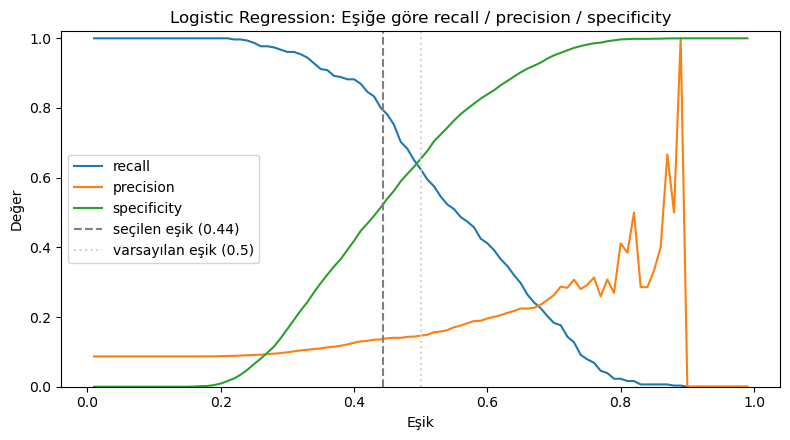

In [11]:
table, threshold = threshold_analysis(result["y"], result["oof_score"], model_name=MODEL_NAME)

## 7. Katsayıların yorumlanması

Logistic Regression'ın kendi açıklaması katsayılarıdır. Özellikler standartlaştırıldığı için katsayılar birbiriyle karşılaştırılabilir:

- **Katsayı > 0:** özellik arttıkça inme riski artar; **< 0:** azalır.
- **Odds ratio = e^katsayı:** sürekli bir özellik **1 standart sapma** arttığında (0/1 özelliklerde 0'dan 1'e geçildiğinde) inme odds'unun kaç katına çıktığı. Örneğin 1.5 = odds %50 artar, 0.8 = odds %20 azalır.
- L1 cezası seçildiyse bazı katsayılar tam 0 olabilir: model o özelliği kullanmıyor demektir.

**Uyarı:** Birbirine bağlı özellikler (ör. `SYSBP`, `DIABP`, `pulse_pressure`, `mean_arterial_pressure`) aynı bilgiyi paylaştığı için katsayıları tek tek yorumlanırken dikkatli olunmalıdır (çoklu doğrusallık). Biri büyük pozitif, diğeri negatif çıkabilir; ikisinin toplam etkisine bakmak gerekir.

In [12]:
feature_names = best.named_steps["encode"].get_feature_names_out()
coefs = pd.DataFrame({
    "feature": feature_names,
    "coefficient": best.named_steps["model"].coef_[0],
})
coefs["odds_ratio"] = np.exp(coefs["coefficient"])
coefs = coefs.reindex(coefs["coefficient"].abs().sort_values(ascending=False).index).reset_index(drop=True)
print("Sıfır olan katsayı sayısı:", (coefs["coefficient"] == 0).sum(), "/", len(coefs))
coefs.round(3)

Sıfır olan katsayı sayısı: 0 / 28


,feature,coefficient,odds_ratio
0,AGE,0.336,1.399
1,SEX_female,-0.212,0.809
2,DIABP,0.113,1.119
3,comorbidity_count,0.110,1.116
4,mean_arterial_pressure,0.104,1.109
5,SYSBP,0.082,1.086
6,HEARTRTE,-0.079,0.924
7,educ,-0.075,0.927
8,PREVCHD,-0.060,0.941
9,bp_stage_normal,-0.060,0.942


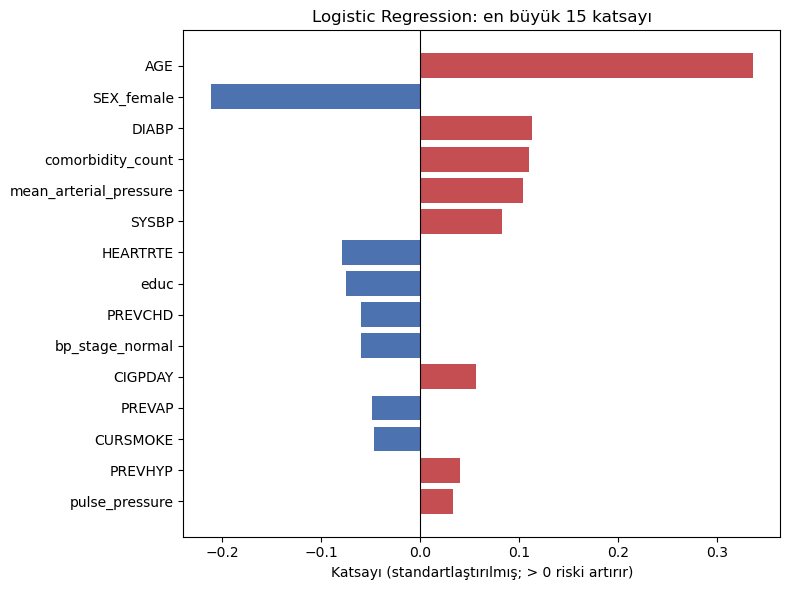

In [13]:
top = coefs[coefs["coefficient"] != 0].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["coefficient"], color=np.where(top["coefficient"] > 0, "#C44E52", "#4C72B0"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Katsayı (standartlaştırılmış; > 0 riski artırır)")
ax.set_title(f"{MODEL_NAME}: en büyük 15 katsayı")
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_coefficients.png", dpi=200)
plt.show()

## 8. Test seti değerlendirmesi

Final model tüm eğitim verisiyle yeniden eğitilir ve test setinde **yalnızca bir kez**, Bölüm 6'da seçilen eşikle değerlendirilir. CV ile test sonuçları yakınsa model yeni veriye iyi genelleniyor demektir.

===== Logistic Regression: Test seti (eşik = 0.444) =====
61/77 inme yakalandı, 16 inme kaçırıldı, 361 yanlış alarm (881 kişi).

             cv_same_threshold   test  cv_minus_test
recall                   0.801  0.792          0.008
precision                0.138  0.145         -0.006
f1                       0.236  0.244         -0.008
specificity              0.526  0.551         -0.025
roc_auc                  0.713  0.765         -0.052
pr_auc                   0.195  0.250         -0.055
accuracy                 0.550  0.572         -0.023


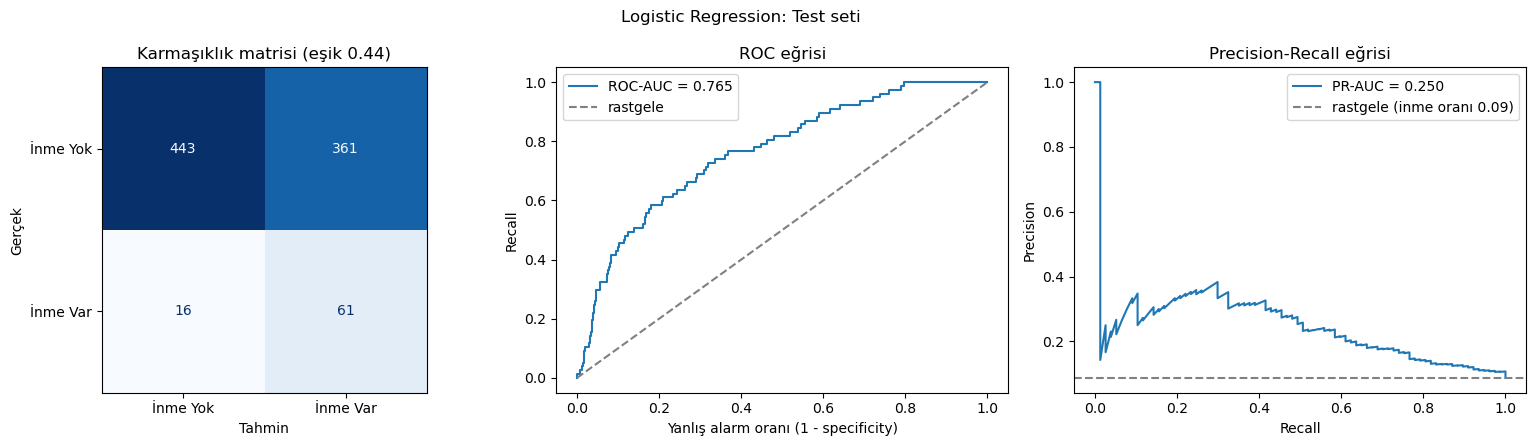

In [14]:
best.fit(X_train, y_train)
test = test_evaluate(best, X_test, y_test, threshold=threshold, model_name=MODEL_NAME, cv_result=result)

In [15]:
joblib.dump({"model": best, "threshold": threshold, "params": search.best_params_,
             "balancing": best_balancing}, MODEL_DIR / f"{MODEL_CODE}.joblib")
print("Kaydedildi:", MODEL_DIR / f"{MODEL_CODE}.joblib")

Kaydedildi: /Users/elifsenasoysal/Documents/GitHub/stroke_detection_ML/models/lr.joblib


## 9. Açıklanabilir yapay zeka (SHAP + LIME)

Ortak `explain()` fonksiyonu kullanılır. Logistic Regression için SHAP otomatik olarak **LinearExplainer** seçer: model zaten bir formül (katsayı × özellik) olduğu için SHAP değerleri bu formülden doğrudan ve kesin olarak hesaplanır, çok hızlıdır. SHAP değerleri **log-odds** ölçeğindedir; diğer modellerle karşılaştırırken `compare_importance()` yüzdeleri kullanılmalıdır.

- **SHAP (global):** model genel olarak hangi özelliklere dayanıyor ve yönü ne?
- **LIME (lokal):** modelin en riskli gördüğü test hastası için kararın gerekçesi.

XAI fonksiyonuna arama nesnesi değil, en iyi model (`search.best_estimator_` = `best`) verilir. Grafikler `figures/` klasörüne de kaydedilir.

===== Logistic Regression: XAI Analizi =====


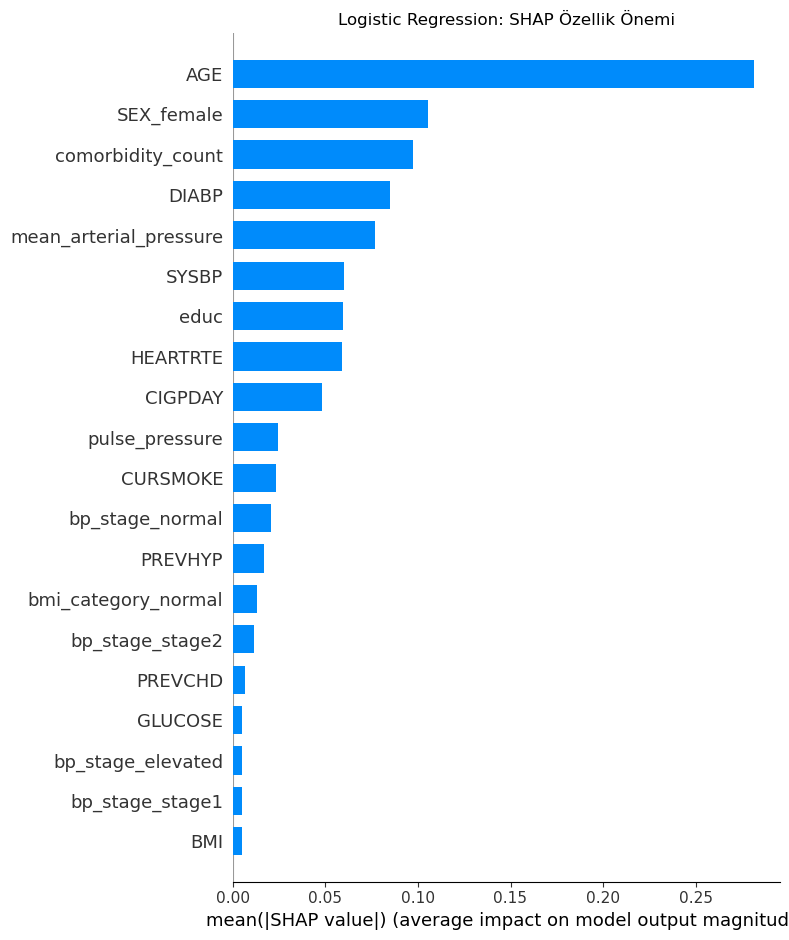

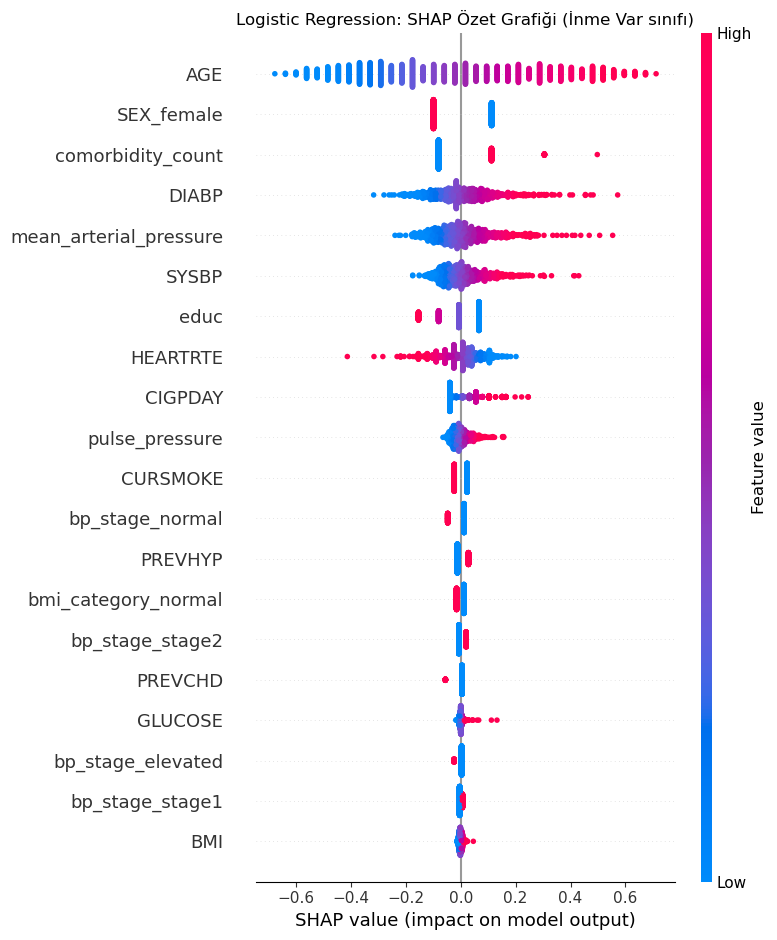


En önemli 5 özellik (SHAP):
               feature  mean_abs_shap
                   AGE       0.281471
            SEX_female       0.105275
     comorbidity_count       0.097262
                 DIABP       0.084808
mean_arterial_pressure       0.076699

[Logistic Regression] Test hastası #789: İnme olasılığı = 85.29%


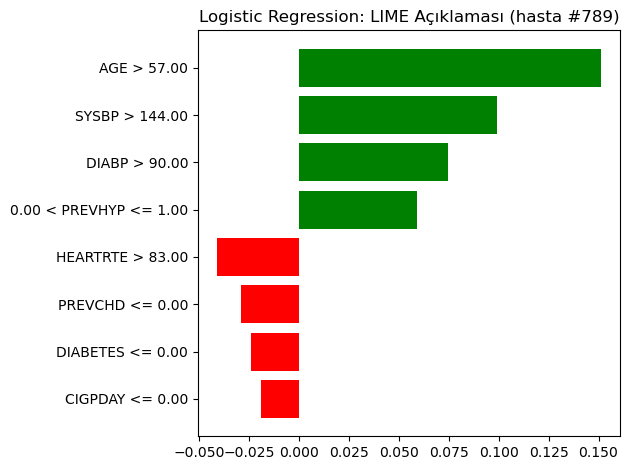

In [16]:
# explain() shows its three figures with plt.show(); save each one to figures/ before it is shown
fig_names = iter([f"{MODEL_CODE}_shap_bar.png", f"{MODEL_CODE}_shap_summary.png", f"{MODEL_CODE}_lime.png"])
_show = plt.show

def _save_then_show(*args, **kwargs):
    name = next(fig_names, None)
    if name:
        plt.gcf().savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    _show(*args, **kwargs)

plt.show = _save_then_show
try:
    xai = explain(best, X_train, X_test, model_name=MODEL_NAME)
finally:
    plt.show = _show

In [17]:
xai["shap_importance"].head(10).round(3)

,feature,mean_abs_shap
0,AGE,0.281
1,SEX_female,0.105
2,comorbidity_count,0.097
3,DIABP,0.085
4,mean_arterial_pressure,0.077
5,SYSBP,0.060
6,educ,0.059
7,HEARTRTE,0.059
8,CIGPDAY,0.048
9,pulse_pressure,0.024


In [18]:
# SHAP importance vs. coefficient magnitude: do the two explanations agree?
shap_rank = xai["shap_importance"].set_index("feature")["mean_abs_shap"].rank(ascending=False)
coef_rank = coefs.set_index("feature")["coefficient"].abs().rank(ascending=False)
pd.DataFrame({"shap_rank": shap_rank, "coef_rank": coef_rank}).sort_values("shap_rank").head(10).astype(int)

,shap_rank,coef_rank
feature,,
AGE,1,1
SEX_female,2,2
comorbidity_count,3,4
DIABP,4,3
mean_arterial_pressure,5,5
SYSBP,6,6
educ,7,8
HEARTRTE,8,7
CIGPDAY,9,11


## 10. Özet (rapor için)

- **Model:** Logistic Regression (L2, C = 0.001, SMOTE). En iyi ayar 5 katlı CV'de PR-AUC'ye göre GridSearch ile seçildi (2 dengeleme × 2 ceza × 5 C = 20 kombinasyon). class_weight ile en iyi ayar (C = 0.01) neredeyse aynı skoru verdi (fark CV standart sapmasının altında).
- **CV sonucu (eşik 0.5):** PR-AUC 0.208 ± 0.022, ROC-AUC 0.716 ± 0.034, recall 0.62, precision 0.15. Rastgele bir modelin PR-AUC'si inme oranına (≈ 0.087) eşittir; model bunun yaklaşık 2,4 katı.
- **Overfitting yok:** eğitim ile CV arasındaki PR-AUC farkı 0.001. Öğrenme eğrisinde iki eğri birbirine yakın ve düşük: model ezberlemiyor, ama doğrusal yapısı nedeniyle verideki örüntünün bir kısmını yakalayamıyor olabilir (hafif underfitting). Güçlü düzenlileştirmenin seçilmesi de verideki sinyalin sınırlı olduğunu gösteriyor.
- **Karar eşiği:** test setine bakılmadan, CV tahminlerinde recall ≥ %80 sağlayan en yüksek eşik olarak 0.444 seçildi.
- **Test seti (eşik 0.444):** 77 inmenin 61'i yakalandı (recall 0.79), 16'sı kaçırıldı; karşılığında 881 kişide 361 yanlış alarm (precision 0.145, specificity 0.55). ROC-AUC 0.765, PR-AUC 0.250. Test sonuçları CV'ye yakın, hatta biraz daha iyi: model yeni veriye genelleniyor.
- **Açıklanabilirlik:** Hem katsayılar hem SHAP en önemli özelliği **yaş** olarak gösteriyor (1 std artış inme odds'unu yaklaşık 1,4 katına çıkarıyor). Ardından **cinsiyet** (kadınlarda risk daha düşük), **eşlik eden hastalık sayısı** ve **tansiyon** (DIABP, ortalama arter basıncı, SYSBP) geliyor. Bu sıralama Framingham'ın klinik inme risk profiliyle (yaş, tansiyon, diyabet, kalp hastalığı) uyumlu. SHAP ve katsayı sıralamaları ilk 6 özellikte birebir aynı, çünkü LinearExplainer SHAP'ı doğrudan katsayılardan hesaplıyor.
- **Dikkat edilecek nokta:** DIABETES ve PREVCHD'nin katsayıları beklenenin tersine hafif negatif. Bunun nedeni çoklu doğrusallık: bu iki sütunun bilgisi `comorbidity_count` (DIABETES + PREVHYP + PREVCHD) tarafından zaten taşınıyor, model riski o sütun üzerinden veriyor. Aynı durum sigarada da var: `CURSMOKE` hafif negatif, `CIGPDAY` pozitif; risk günlük sigara sayısı üzerinden veriliyor. `HEARTRTE`'nin negatif çıkması (yüksek nabız → düşük risk) ise klinik olarak beklenmeyen bir bulgu; nedensel değil, bu verideki bir ilişki olarak yorumlanmalı.
- **Avantaj / dezavantaj:** Hızlı (kat başına 0,02 sn), yorumlanabilir ve klinik bilgiyle tutarlı. Ancak yalnızca doğrusal ilişki öğrendiği için eşik etkilerini ve etkileşimleri kendisi bulamıyor; ağaç modellerinin bu konuda bir şey kazandırıp kazandırmadığı karşılaştırmada görülecek.